In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("All libraries loaded")

All libraries loaded


In [2]:
df = pd.read_csv("data/car.csv")
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [3]:
print(df.shape)
df.info()
print(df.isnull().sum())
df.describe()


(301, 9)
<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    str    
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    str    
 6   Seller_Type    301 non-null    str    
 7   Transmission   301 non-null    str    
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 30.0 KB
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64


,Year,Selling_Price,Present_Price,Kms_Driven,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.644115,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


In [4]:
for col in df.select_dtypes(include="object").columns:
    print(col, df[col].unique()[:10])

Car_Name <ArrowStringArray>
[         'ritz',           'sx4',          'ciaz',       'wagon r',
         'swift', 'vitara brezza',       's cross',      'alto 800',
        'ertiga',         'dzire']
Length: 10, dtype: str
Fuel_Type <ArrowStringArray>
['Petrol', 'Diesel', 'CNG']
Length: 3, dtype: str
Seller_Type <ArrowStringArray>
['Dealer', 'Individual']
Length: 2, dtype: str
Transmission <ArrowStringArray>
['Manual', 'Automatic']
Length: 2, dtype: str


C:\Users\JUVVALADINNE ALEKHYA\AppData\Local\Temp\ipykernel_22224\283005218.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


In [5]:
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()
print(df.shape)
print(df.columns.tolist())

Duplicates: 2
(299, 9)
['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner']


In [6]:
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()
print(df.shape)
print(df.columns.tolist())

Duplicates: 0
(299, 9)
['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner']


In [7]:
df["Car_Age"] = 2026 - df["Year"]
df = df.drop(columns=["Year", "Car_Name"])
df.head()

,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Car_Age
0,3.35,5.59,27000,Petrol,Dealer,Manual,0,12
1,4.75,9.54,43000,Diesel,Dealer,Manual,0,13
2,7.25,9.85,6900,Petrol,Dealer,Manual,0,9
3,2.85,4.15,5200,Petrol,Dealer,Manual,0,15
4,4.60,6.87,42450,Diesel,Dealer,Manual,0,12


In [8]:
df = pd.get_dummies(df, columns=["Fuel_Type", "Seller_Type", "Transmission"], drop_first=True)
df = df.astype(float)
df.head()

,Selling_Price,Present_Price,Kms_Driven,Owner,Car_Age,Fuel_Type_Diesel,Fuel_Type_Petrol,Seller_Type_Individual,Transmission_Manual
0,3.35,5.59,27000.0,0.0,12.0,0.0,1.0,0.0,1.0
1,4.75,9.54,43000.0,0.0,13.0,1.0,0.0,0.0,1.0
2,7.25,9.85,6900.0,0.0,9.0,0.0,1.0,0.0,1.0
3,2.85,4.15,5200.0,0.0,15.0,0.0,1.0,0.0,1.0
4,4.60,6.87,42450.0,0.0,12.0,1.0,0.0,0.0,1.0


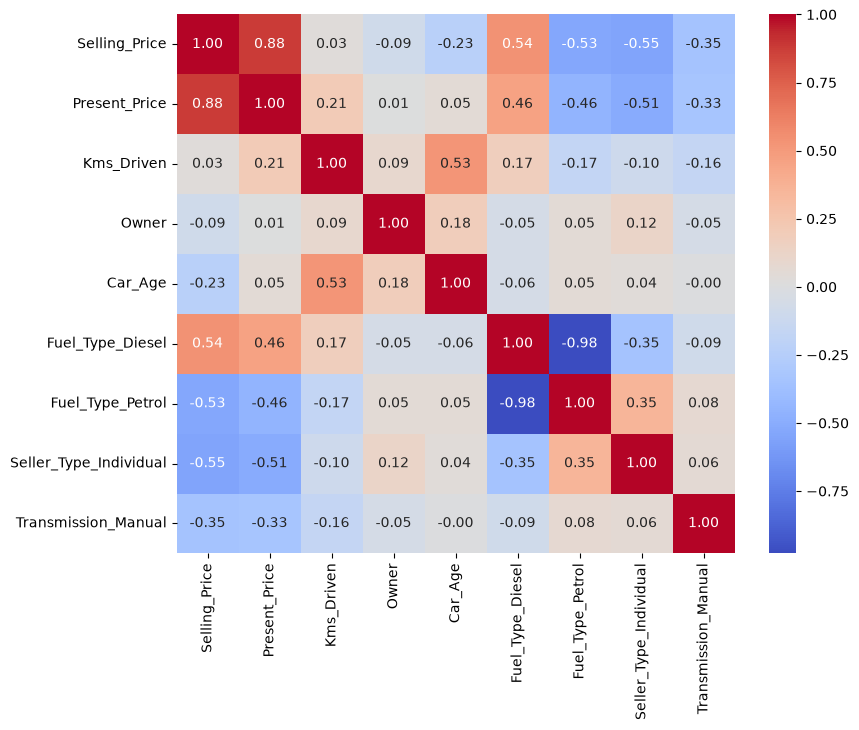

In [9]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.show()

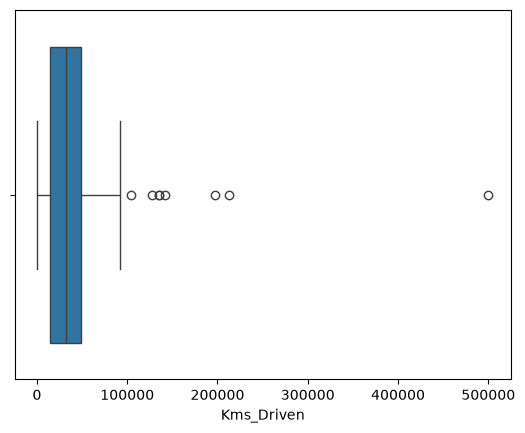

In [10]:
sns.boxplot(x=df["Kms_Driven"])
plt.show()